# Ordered beta and zero-one-inflated beta

We use the real `pew` dataset from R's `ordbetareg`, following its
[feeling thermometer example](https://saudiwin.github.io/ordbetareg_pack/vignettes/package_introduction.html).
Respondents rate college professors from 0 to 100, including both endpoints.
We divide by 100 and model the rating by education. This is a simplified
adaptation, not the same model as in the original example. The R model uses
`mo(education)` and `mo(income)` to estimate monotonic effects of ordinal
predictors. Bambi has no equivalent to `mo()`, so we treat education as
categorical, with unconstrained effects for its levels. We also omit income,
its interaction with education, and the regional effects.

In [1]:
%matplotlib inline

import arviz as az
import bambi as bmb
import matplotlib.pyplot as plt
import pandas as pd

from bambi import interpret

plt.style.use("../bambi.mplstyle")

In [2]:
url = "https://saudiwin.r-universe.dev/ordbetareg/data/pew/csv"
data = pd.read_csv(
    url,
    usecols=["therm", "F_EDUCCAT2_FINAL"],
    storage_options={"User-Agent": "Mozilla/5.0"},
)
education_labels = {
    "Less than high school": "Less than HS",
    "High school graduate": "High school",
    "Some college, no degree": "Some college",
    "Associate’s degree": "Associate",
    "College graduate/some postgrad": "College",
    "Postgraduate": "Postgraduate",
}
data["education"] = data["F_EDUCCAT2_FINAL"].map(education_labels)
data = data.dropna(subset=["therm", "education"]).copy()
data["education"] = pd.Categorical(
    data["education"], categories=list(education_labels.values())
)
data["rating"] = data["therm"] / 100

pd.Series(
    {
        "Respondents": len(data),
        "Proportion at zero": data["rating"].eq(0).mean(),
        "Proportion at one": data["rating"].eq(1).mean(),
    }
)

Respondents           2532.000000
Proportion at zero       0.047393
Proportion at one        0.089652
dtype: float64

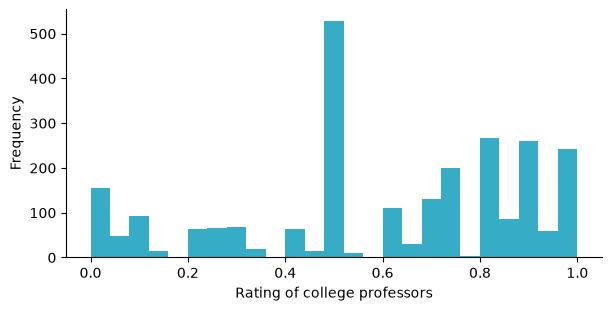

In [3]:
data["rating"].plot.hist(bins=25, figsize=(6, 3))
plt.xlabel("Rating of college professors")
plt.show()

## Ordered beta

The same linear predictor controls the interior beta mean `mu` and the endpoint
probabilities. Two ordered cutpoints govern the probabilities of zero and one,
while `kappa` controls the precision of the beta component.

In [4]:
ordered = bmb.Model("rating ~ education", data, family="ordered_beta")
ordered_idata = ordered.fit(target_accept=0.9, random_seed=1234)
az.summary(ordered_idata, var_names=["education", "kappa", "cut0", "logdelta"])

NUTS[nutpie]: [kappa, cut0, logdelta, education, Intercept_centered]


Output()

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
education[College],0.218,0.074,0.1,0.34,1420,1990,1.00,0.002,0.0011
education[High school],-0.133,0.087,-0.27,0.0075,1821,2456,1.00,0.002,0.0012
education[Less than HS],0.111,0.137,-0.11,0.33,3024,2618,1.00,0.0025,0.0021
education[Postgraduate],0.491,0.075,0.37,0.61,1475,1921,1.00,0.0019,0.0011
education[Some college],-0.021,0.078,-0.15,0.1,1484,2053,1.00,0.002,0.0012
kappa,2.914,0.078,2.8,3,5440,2869,1.00,0.0011,0.0014
cut0,-2.716,0.094,-2.9,-2.6,2061,2592,1.00,0.0021,0.0013
logdelta,1.6782,0.0208,1.6,1.7,1982,2449,1.00,0.00047,0.0003


`interpret.predictions` returns `.summary` and `.draws`. Its default
`target="mean"` returns `mu`, the mean **conditional on being in the beta component**,
not the overall expected rating. These are 90% credible intervals for `mu`.

In [5]:
interpret.predictions(ordered, ordered_idata, conditional="education", prob=0.9).summary

,education,estimate,lower_5.0%,upper_95.0%
0,Less than HS,0.559518,0.510942,0.608007
1,High school,0.499139,0.475416,0.523325
2,Some college,0.526966,0.507517,0.544460
3,Associate,0.532273,0.505953,0.559065
4,College,0.586004,0.570809,0.600866
5,Postgraduate,0.650272,0.635790,0.664662


With `target="rating"`, `interpret` draws a new response from the full mixture,
including zeros and ones. Its intervals describe individual ratings, so they can
be much wider than intervals for `mu`. With `use_hdi=False` and `prob=0.9`, the
bounds are the 5th and 95th percentiles. If each endpoint has more than 5%
predictive probability, the interval spans [0, 1], even with well-estimated parameters.

In [6]:
ordered_predictive = interpret.predictions(
    ordered,
    ordered_idata,
    conditional="education",
    target="rating",
    prob=0.9,
    use_hdi=False,
)
ordered_predictive.summary

,education,estimate,lower_5.0%,upper_95.0%
0,Less than HS,0.562517,0.008516,1.0
1,High school,0.501870,0.000000,1.0
2,Some college,0.539944,0.000000,1.0
3,Associate,0.533975,0.000000,1.0
4,College,0.596643,0.056252,1.0
5,Postgraduate,0.668883,0.121102,1.0


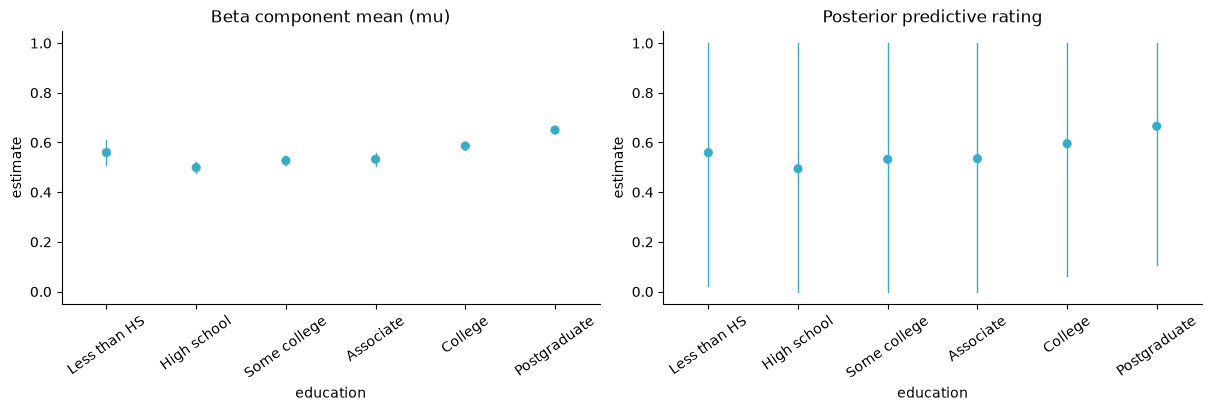

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
interpret.plot_predictions(
    ordered, ordered_idata, conditional="education", prob=0.9, on=axes[0]
)
interpret.plot_predictions(
    ordered,
    ordered_idata,
    conditional="education",
    target="rating",
    prob=0.9,
    use_hdi=False,
    on=axes[1],
)
axes[0].set_title("Beta component mean (mu)")
axes[1].set_title("Posterior predictive rating")
for ax in axes:
    ax.tick_params(axis="x", labelrotation=35)
plt.show()

## Zero-one-inflated beta

Fit the same data with separate models for the interior beta mean, endpoint
frequency `zoi = P(y in {0, 1})`, and the probability of one among endpoint
responses `coi = P(y=1 | y in {0, 1})`. Ordered beta links these processes through
a shared linear predictor, while this specification lets education affect each separately.
The overall expected rating is `(1 - zoi) * mu + zoi * coi`.

In [8]:
inflated = bmb.Model(
    bmb.Formula("rating ~ education", "zoi ~ education", "coi ~ education"),
    data,
    family="zero_one_inflated_beta",
)
inflated_idata = inflated.fit(
    draws=1000, tune=1000, chains=4, cores=4, target_accept=0.9, random_seed=5678
)
az.summary(
    inflated_idata, var_names=["education", "zoi_education", "coi_education", "kappa"]
)

NUTS[nutpie]: [kappa, education, Intercept_centered, zoi_education, zoi_Intercept_centered, coi_education, coi_Intercept_centered]


Output()

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
education[College],0.204,0.079,0.081,0.33,1162,1690,1.00,0.0023,0.0014
education[High school],-0.156,0.091,-0.3,-0.01,1408,2083,1.00,0.0024,0.0014
education[Less than HS],0.087,0.144,-0.14,0.32,2650,2611,1.00,0.0028,0.0021
education[Postgraduate],0.511,0.08,0.39,0.64,1115,1522,1.00,0.0024,0.0014
education[Some college],-0.025,0.082,-0.15,0.11,1192,1966,1.00,0.0024,0.0014
zoi_education[College],-0.39,0.194,-0.7,-0.08,1202,1957,1.00,0.0056,0.0029
zoi_education[High school],-0.03,0.212,-0.38,0.3,1374,1948,1.00,0.0057,0.0031
zoi_education[Less than HS],0.7,0.275,0.25,1.1,1811,2172,1.00,0.0065,0.0041
zoi_education[Postgraduate],-0.62,0.203,-0.94,-0.29,1330,2254,1.00,0.0056,0.0029
zoi_education[Some college],-0.29,0.202,-0.62,0.027,1307,2131,1.00,0.0056,0.003


Use `target="zoi"` or `target="coi"` to inspect the endpoint probabilities.
`target="mean"` still returns `mu`, and `target="rating"` gives new ratings from
the full mixture.

In [9]:
interpret.predictions(
    inflated, inflated_idata, conditional="education", target="coi", prob=0.9
).summary

,education,estimate,lower_5.0%,upper_95.0%
0,Less than HS,0.575945,0.419463,0.711035
1,High school,0.564098,0.456545,0.674023
2,Some college,0.567103,0.470662,0.654498
3,Associate,0.580561,0.479137,0.677570
4,College,0.725404,0.647747,0.799670
5,Postgraduate,0.796166,0.721559,0.874570


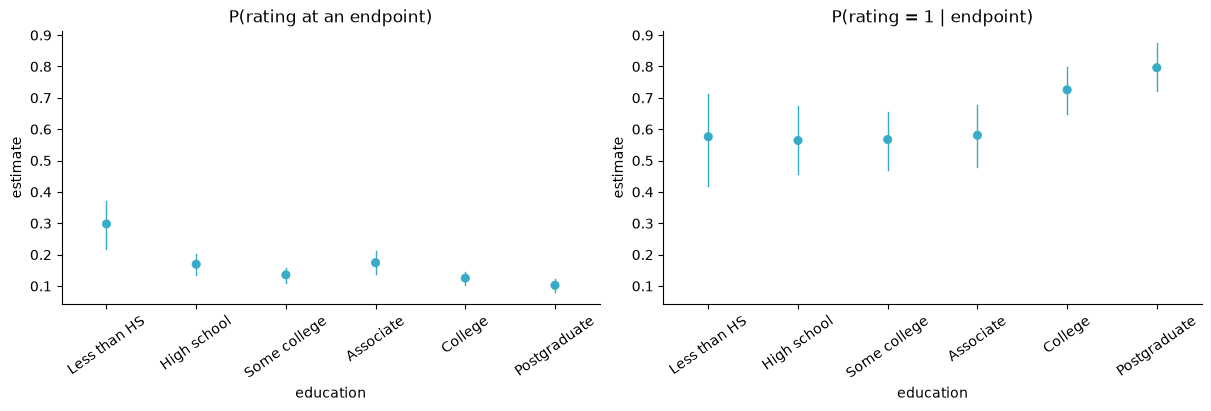

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
interpret.plot_predictions(
    inflated,
    inflated_idata,
    conditional="education",
    target="zoi",
    prob=0.9,
    on=axes[0],
)
interpret.plot_predictions(
    inflated,
    inflated_idata,
    conditional="education",
    target="coi",
    prob=0.9,
    on=axes[1],
)
axes[0].set_title("P(rating at an endpoint)")
axes[1].set_title("P(rating = 1 | endpoint)")
for ax in axes:
    ax.tick_params(axis="x", labelrotation=35)
plt.show()

For a zero-inflated beta with no ones, use this family with `priors={"coi": 0}`
and omit the `coi` formula. As in the original vignette, the survey responses are
heaped at round numbers. These models allow exact endpoints but do not model the
rounding inside the interval.